# Leakage-aware Alzheimer MRI classification

**TL;DR.** This notebook audits 40,384 MRI images, shows why a naive random split is unsafe,
builds original-only holdouts with a perceptual-hash leakage guard, and compares a classical
baseline against a compact CNN on the same clean test set. The data are educational and the
models are **not medical diagnostic systems**.

## Questions

1. Are all images readable and labels structurally complete?
2. How imbalanced are the original and augmented collections?
3. Do transformed copies cross the two collections — and would a random split leak them?
4. What do reproducible models achieve on held-out original images, and where do they fail?

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
FIG = ROOT / 'docs' / 'figures'
sns.set_theme(style='whitegrid')

audit = json.loads((ROOT / 'results/data_quality/audit_summary.json').read_text())
splits = pd.read_csv(ROOT / 'data/processed/dataset_splits.csv')
baseline = json.loads((ROOT / 'results/baseline/metrics.json').read_text())
audit['total_files'], audit['readable_files']

(40384, 40384)

## 1. Dataset inventory

dataset,augmented,original
label,,
MildDemented,8960,896
ModerateDemented,6464,64
NonDemented,9600,3200
VeryMildDemented,8960,2240


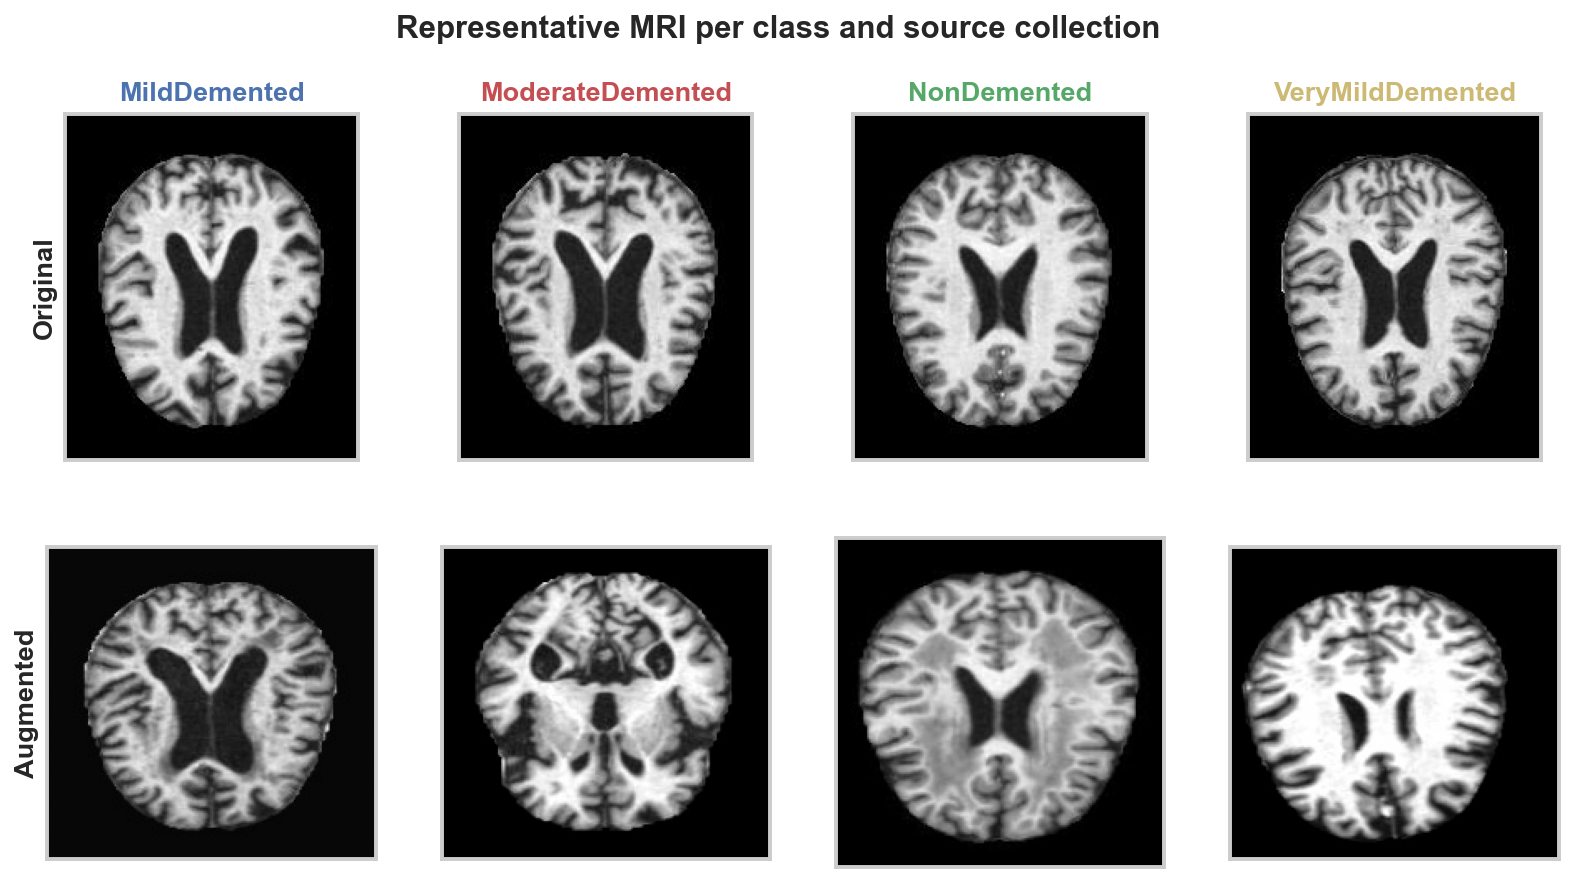

In [2]:
counts = pd.DataFrame(audit['class_counts'])
display(counts.pivot(index='label', columns='dataset', values='count'))
display(Image(filename=FIG / 'class_montage.png'))

The augmented collection is larger and more even, but augmented images are **not**
        independent patients. The original moderate-dementia class has only **64** images, so its
        evaluation metrics carry high uncertainty.

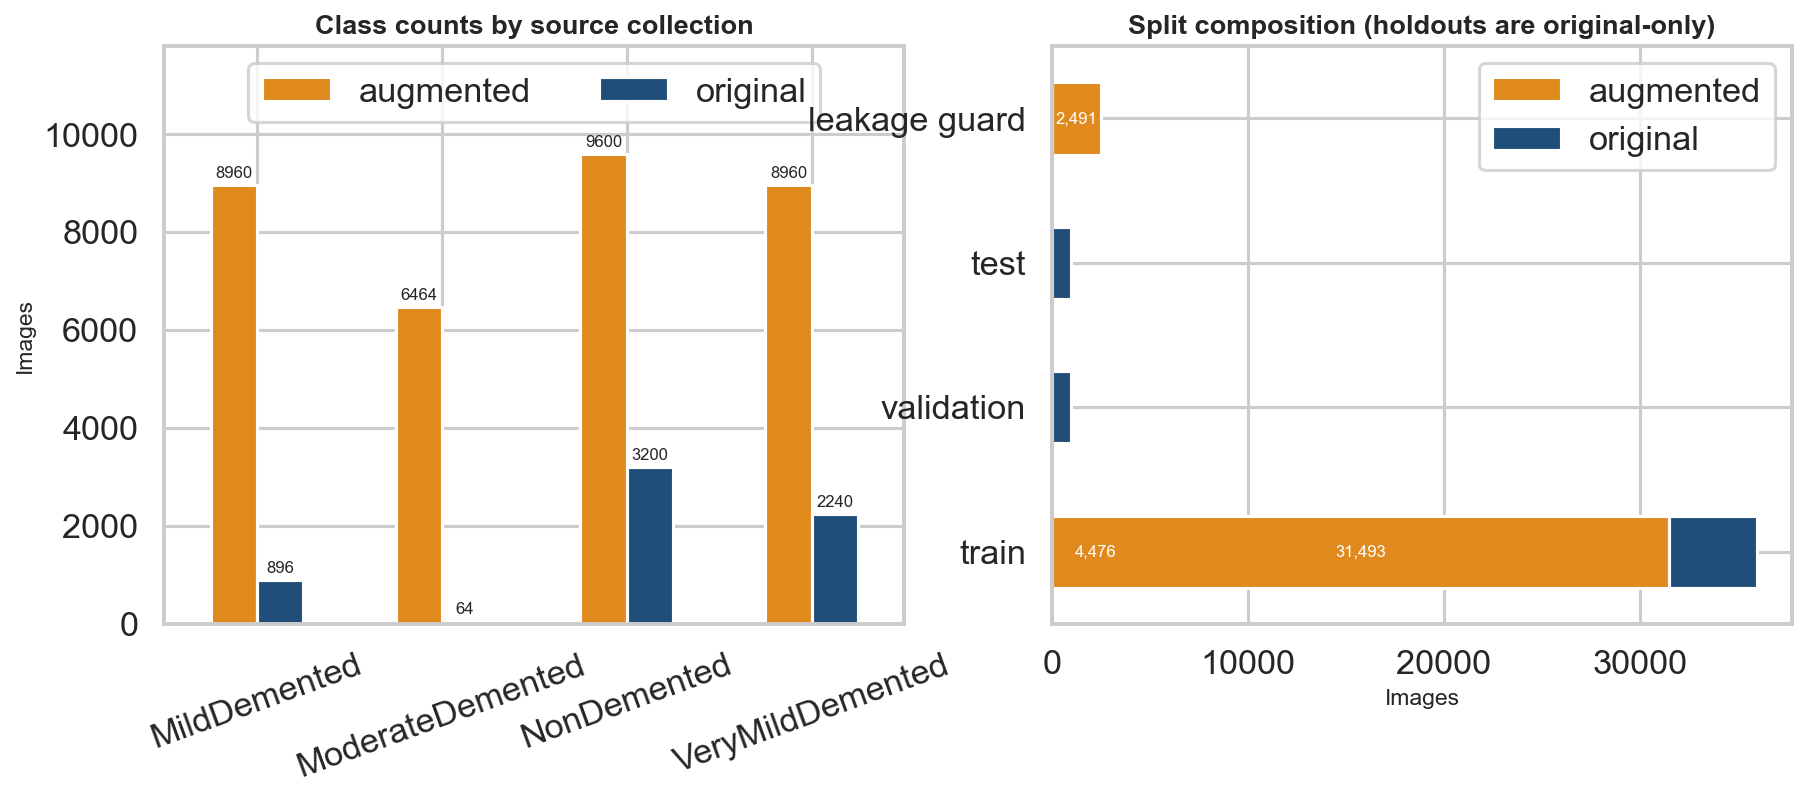

In [3]:
display(Image(filename=FIG / 'distributions.png'))

## 2. Duplicate and leakage audit

In [4]:
pd.Series({
    'Exact-duplicate rows': audit['exact_duplicate_rows'],
    'Perceptual-duplicate rows': audit['perceptual_duplicate_rows'],
    'Cross-source exact groups': audit['cross_dataset_exact_hash_groups'],
    'Cross-source perceptual groups': audit['cross_dataset_perceptual_hash_groups'],
}).to_frame('count')

,count
Exact-duplicate rows,657
Perceptual-duplicate rows,14981
Cross-source exact groups,0
Cross-source perceptual groups,3626


Byte hashes alone miss re-encoded or transformed copies: no exact-hash group crosses
        sources, yet thousands of same-label perceptual groups do. Here is one concrete example.

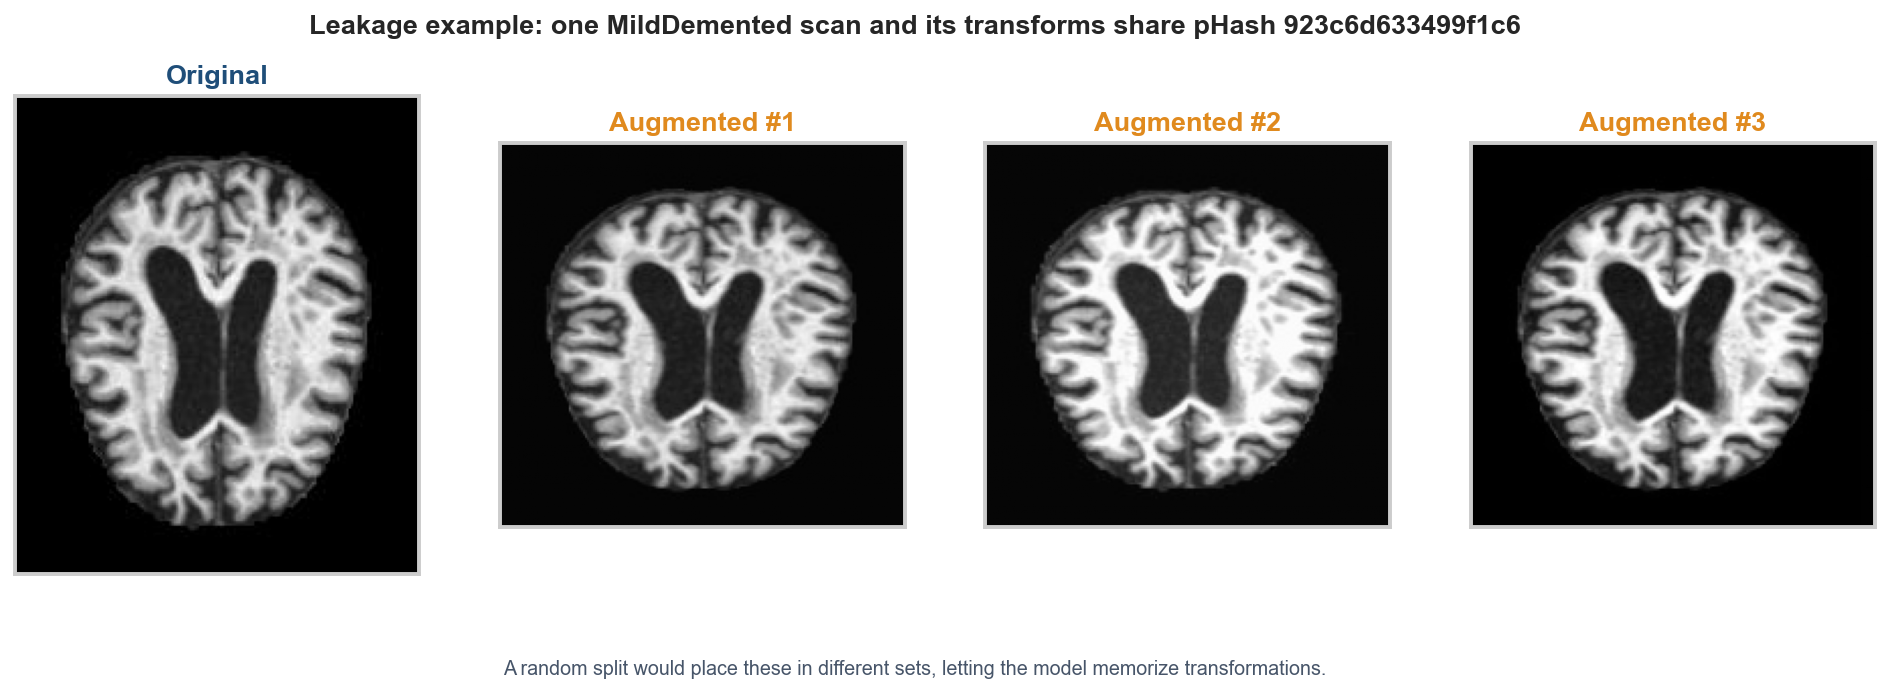

In [5]:
display(Image(filename=FIG / 'leakage_example.png'))

## 3. Leakage-aware split

In [6]:
split_counts = splits.groupby(['split', 'dataset']).size().rename('images').reset_index()
display(split_counts.pivot(index='split', columns='dataset', values='images'))

dataset,augmented,original
split,,
excluded_leakage_guard,2491.0,NaN
test,NaN,963.0
train,31493.0,4476.0
validation,NaN,961.0


In [7]:
held_out = set(splits.loc[splits['split'].isin(['validation', 'test']), 'leakage_group'])
leaking = splits[(splits['split'] == 'train') & splits['leakage_group'].isin(held_out)]
assert leaking.empty, 'leakage guard failed'
assert set(splits.loc[splits['split'].isin(['validation', 'test']), 'dataset']) == {'original'}
print('Leakage assertions passed: no held-out group appears in training.')

Leakage assertions passed: no held-out group appears in training.


Holdouts come only from original images, and every augmented image whose perceptual
        group matches a held-out scan is quarantined. This is stronger than an image-level split
        but is still a proxy for patient-level separation.

## 4. Source cues

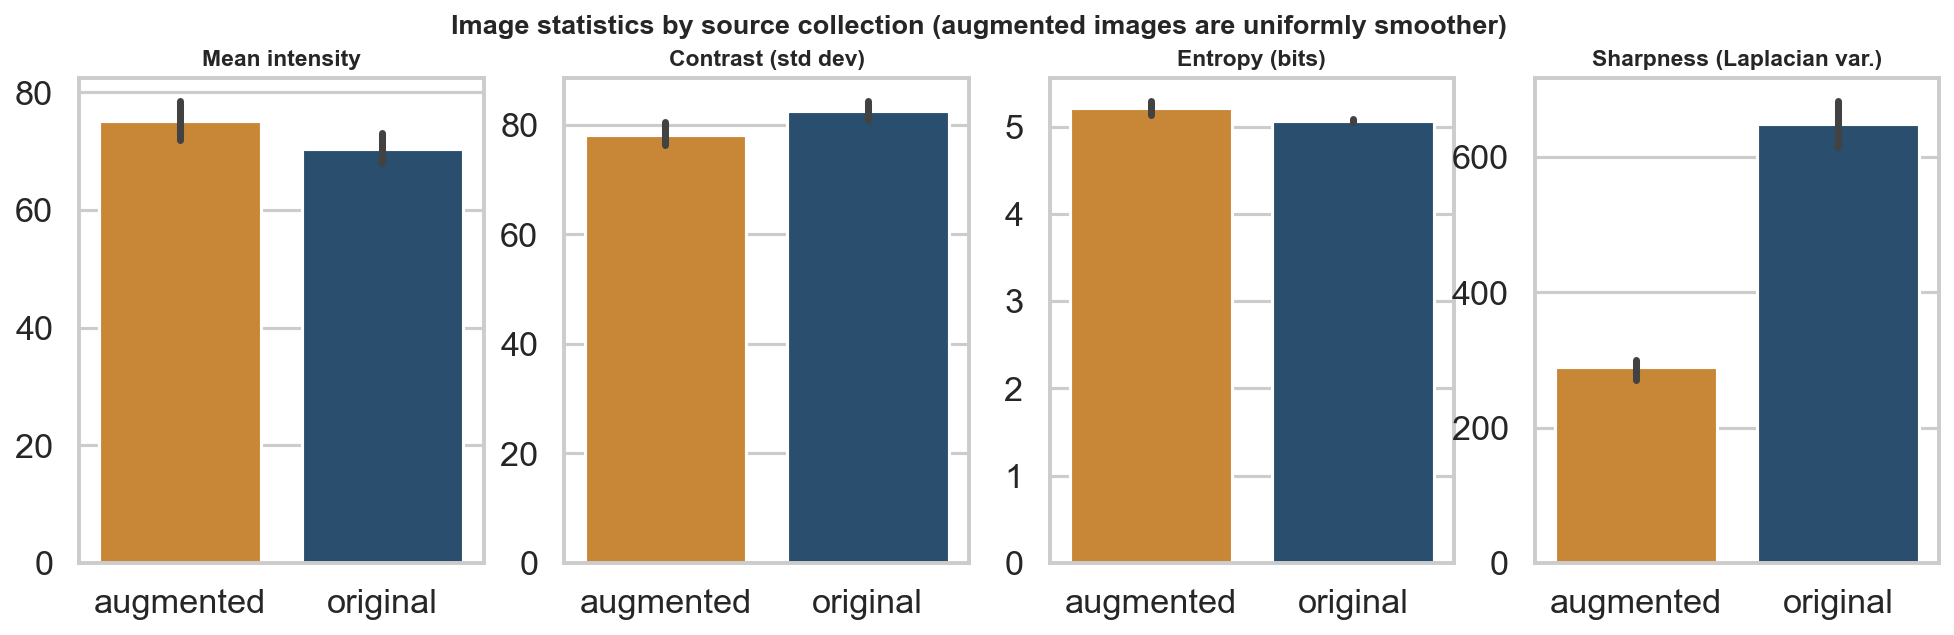

In [8]:
display(Image(filename=FIG / 'source_statistics.png'))

Augmented images are systematically smoother (resizing/interpolation), so a model could
        learn source identity instead of pathology. This is a documented risk, not a fix.

## 5. Held-out results

In [9]:
search = pd.read_csv(ROOT / 'results/baseline/validation_search.csv')
display(search.sort_values('macro_f1', ascending=False))

rows = []
for rel, name in [('results/baseline', 'HOG baseline (all data)'),
                  ('results/baseline_original', 'HOG baseline (original only)')]:
    d = json.loads((ROOT / rel / 'metrics.json').read_text())['test_metrics']
    rows.append({'model': name, 'accuracy': d['accuracy'],
                 'balanced_accuracy': d['balanced_accuracy'], 'macro_f1': d['macro_f1']})
cnn_path = ROOT / 'results/evaluation/metrics.json'
if cnn_path.exists():
    d = json.loads(cnn_path.read_text())
    rows.append({'model': 'Compact CNN (original only)', 'accuracy': d['accuracy'],
                 'balanced_accuracy': d['balanced_accuracy'], 'macro_f1': d['macro_f1']})
display(pd.DataFrame(rows).set_index('model').round(4))

,alpha,accuracy,balanced_accuracy,macro_f1
0,0.00003,0.665973,0.749577,0.649261
1,0.00010,0.663892,0.745927,0.635610
2,0.00030,0.649324,0.736645,0.616166


,accuracy,balanced_accuracy,macro_f1
model,,,
HOG baseline (all data),0.6521,0.7005,0.5975
HOG baseline (original only),0.6262,0.6481,0.5927
Compact CNN (original only),0.5805,0.5862,0.4841


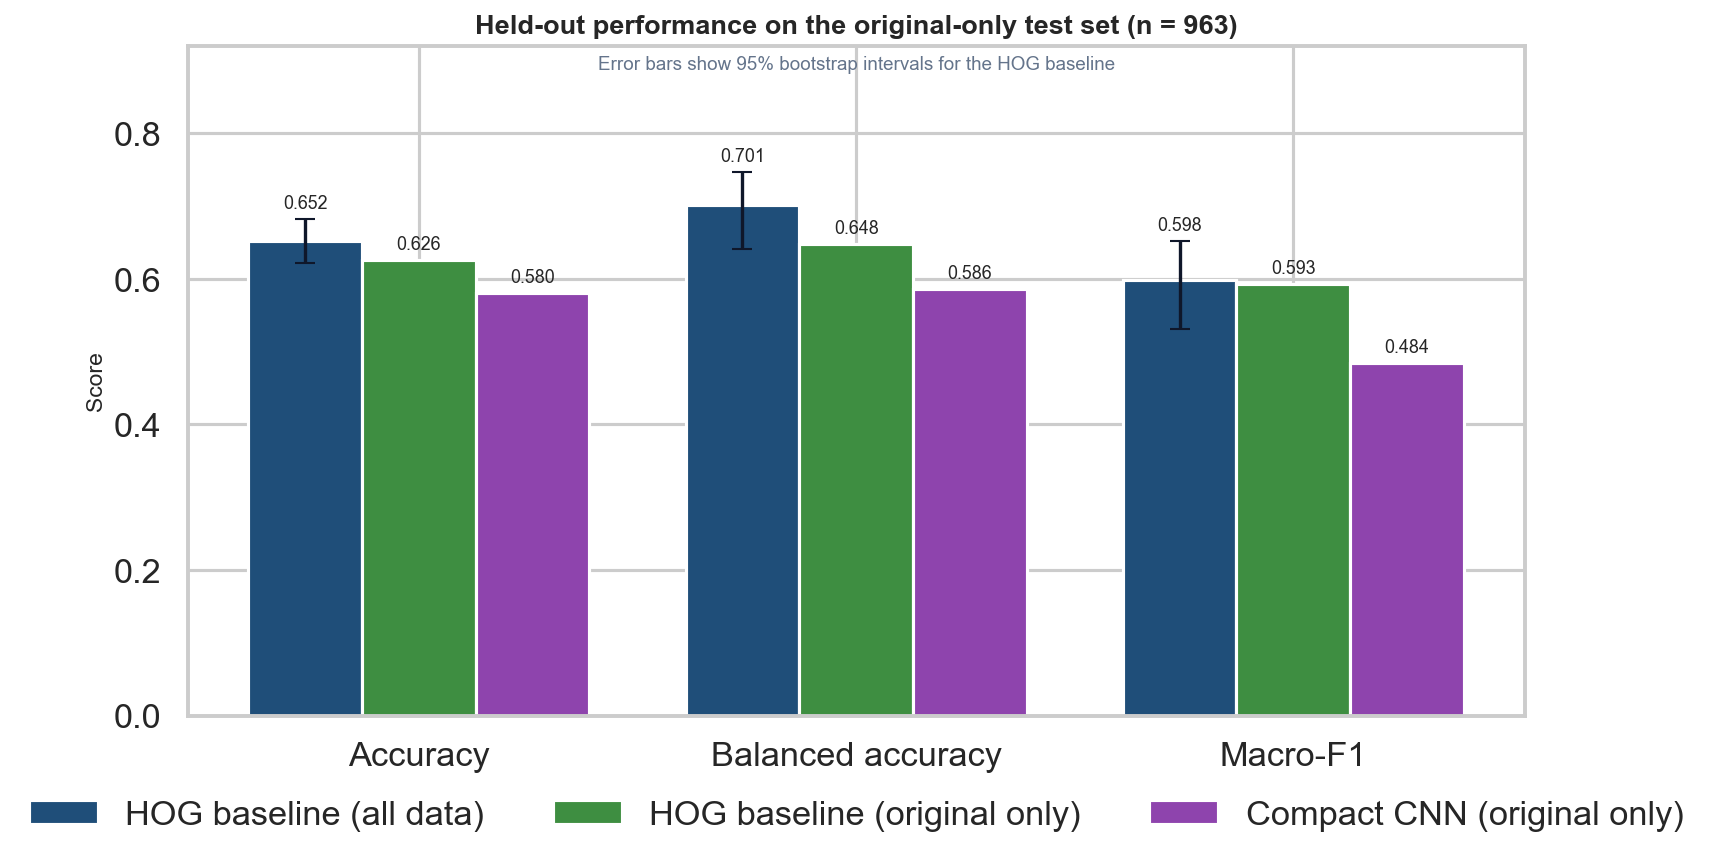

In [10]:
display(Image(filename=FIG / 'model_comparison.png'))

### Ranking quality and calibration

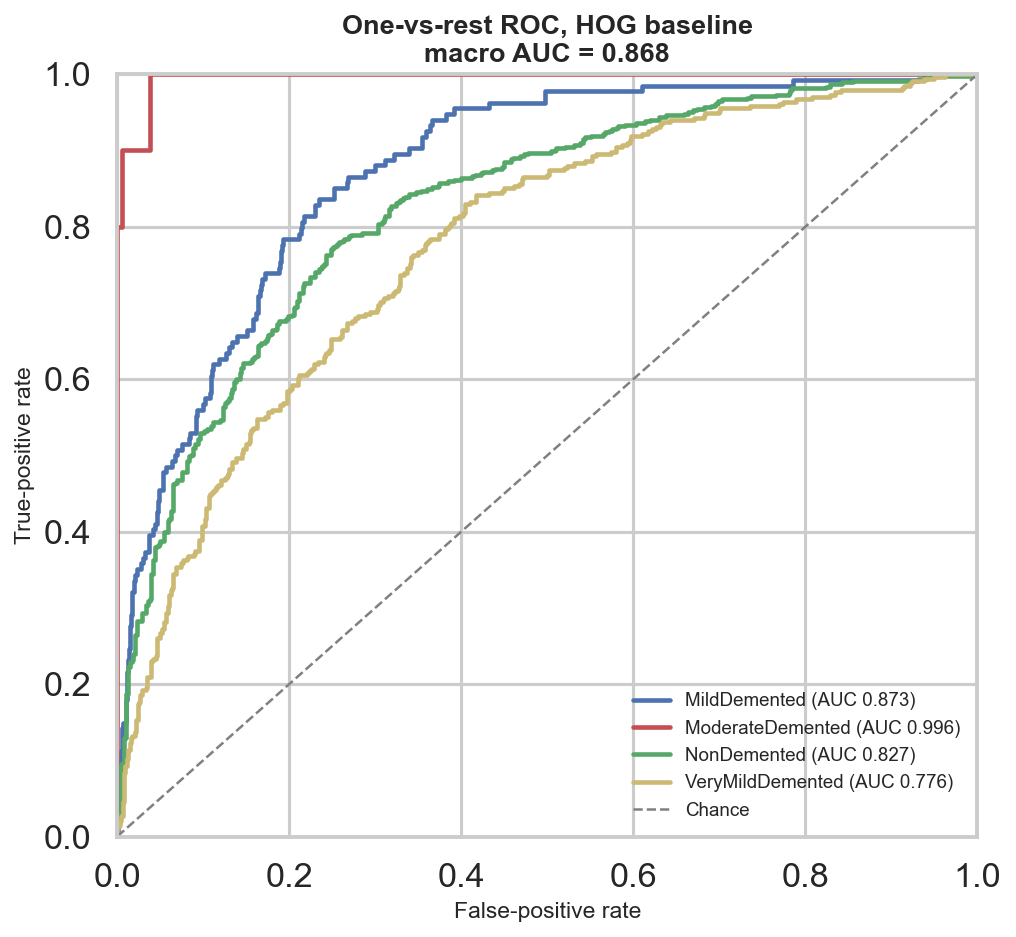

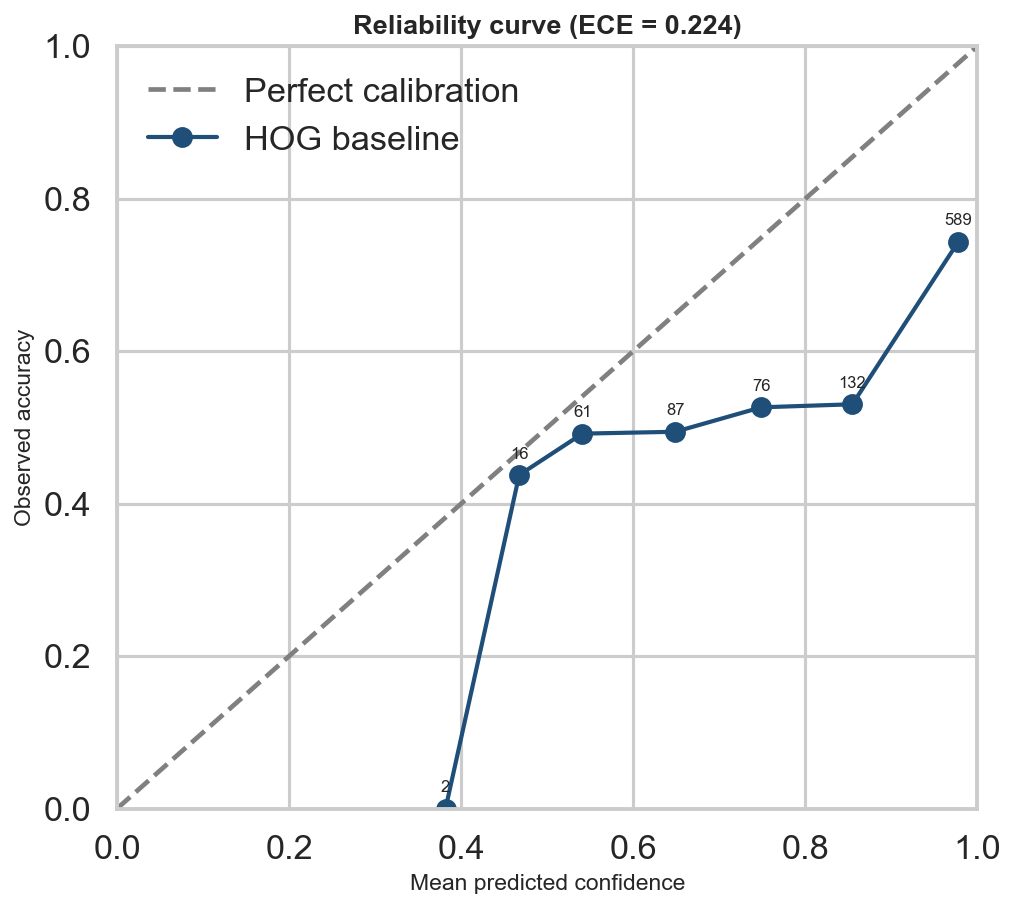

In [11]:
display(Image(filename=FIG / 'roc_curves.png'))
display(Image(filename=FIG / 'calibration.png'))

The baseline ranks classes well (macro ROC-AUC 0.868) but is mildly over-confident. The
        CNN is better calibrated yet less accurate — it lacks data and resolution on CPU.

## 6. Where the model struggles

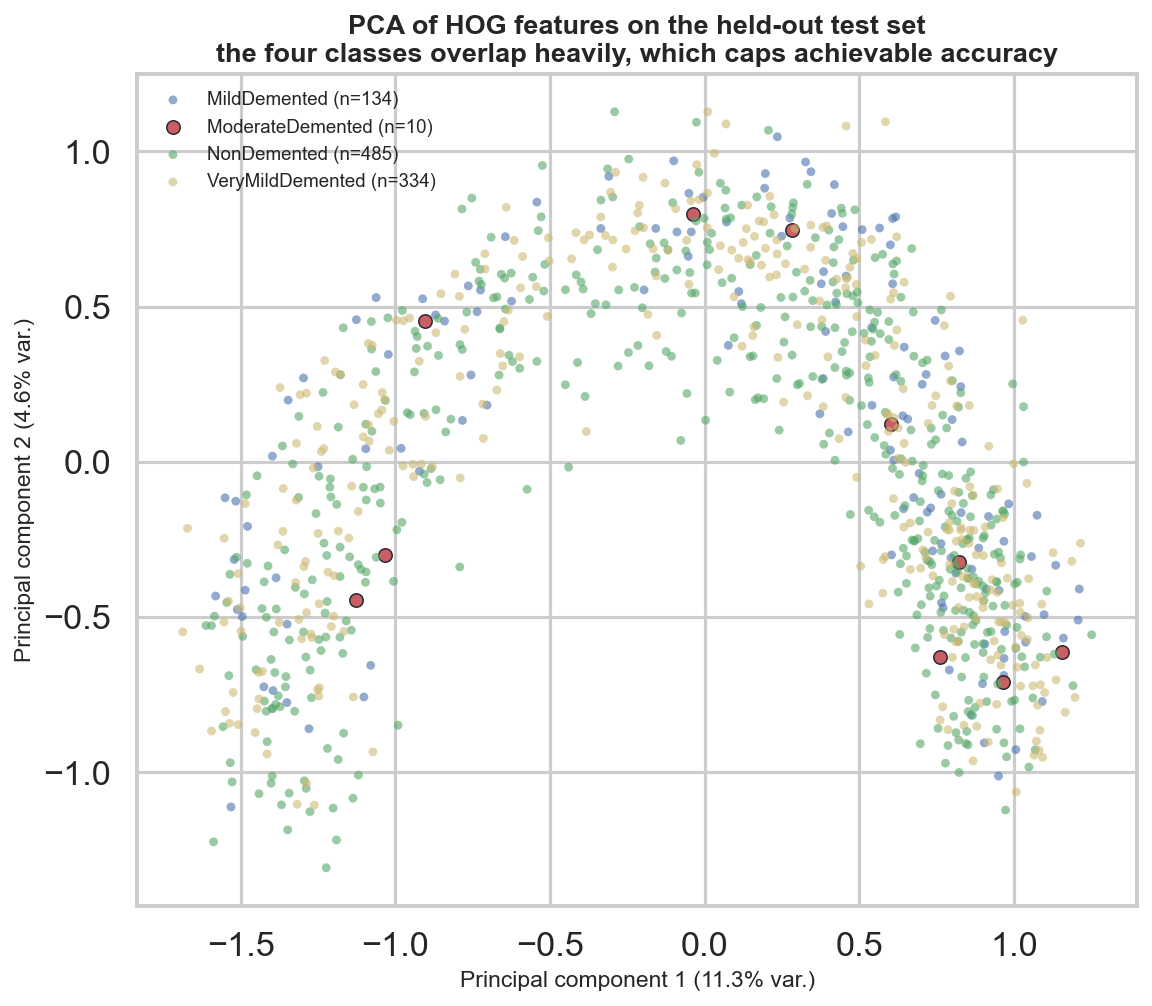

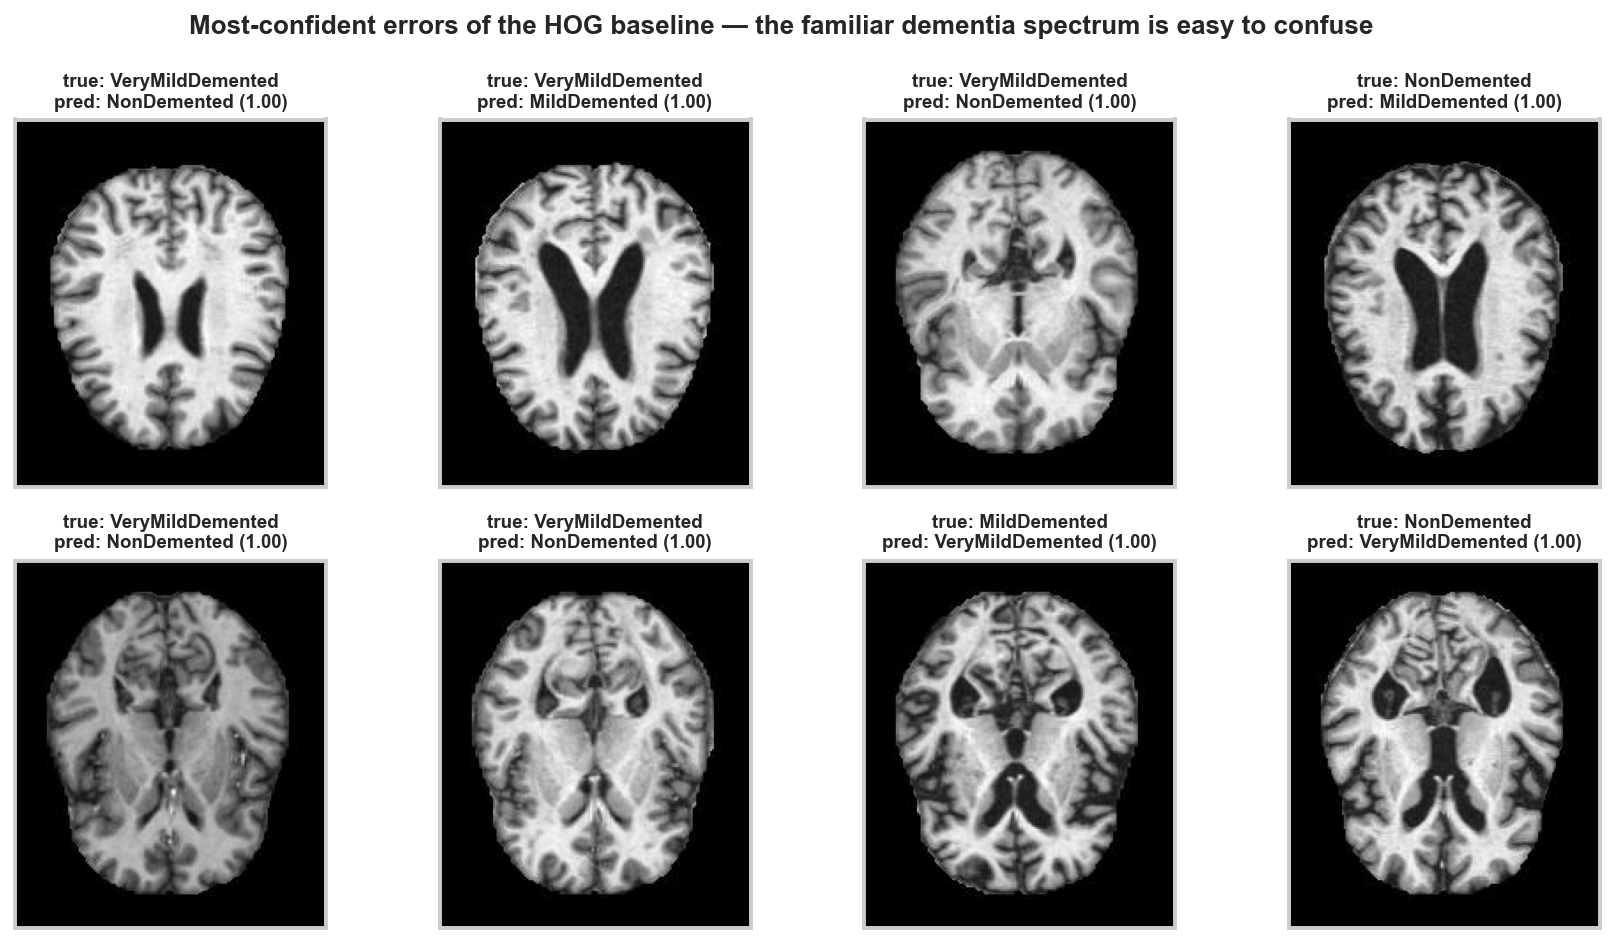

In [12]:
display(Image(filename=FIG / 'hog_embedding.png'))
display(Image(filename=FIG / 'error_gallery.png'))

HOG features barely separate the four classes, and the most-confident errors are visually
        plausible: `VeryMildDemented` vs `NonDemented` and `MildDemented` vs `VeryMildDemented` are
        the hard boundaries. This explains the accuracy ceiling better than any single metric.

## Takeaways

- The central contribution is **leakage-aware, honest evaluation**, not a leaderboard number.
- Macro-F1 and balanced accuracy matter more than accuracy because the labels are imbalanced.
- The moderate-dementia holdout is tiny; its metrics are preliminary.
- Patient-level identifiers and an external cohort are the most important next data requirements.
- A from-scratch CNN does not beat a strong classical descriptor at this data/compute budget.